7×7 tokenwise gradient cosine similarity. Run from the SEAM repository root.

In [ ]:
import json
import os
import os.path as osp

import pandas as pd
import seaborn as sns

path = "artifacts/tamia/tokenwise-cosim-7x7/tokenwise-cosims.jsonl"
outdir = "artifacts/figures"

rows = []
with open(path) as handle:
    for line in handle:
        result = json.loads(line)
        for t, cosine in enumerate(result["cosims"]):
            rows.append(
                {
                    "Token index": t,
                    "Cosine similarity": cosine,
                    "BB": str(result["bb_index"] + 1),
                    "HH": str(result["hh_index"] + 1),
                }
            )

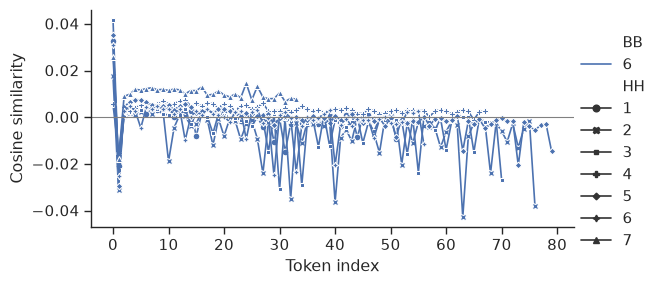

In [7]:
# df limit to 1, 1
df = pd.DataFrame(rows)
sns.set_theme(context="paper", style="ticks", font_scale=1.2)
os.makedirs(outdir, exist_ok=True)

# df = df[(df["BB"] == "1") & (df["HH"] == "1")]
df = df[(df["BB"] == "6")]

grid = sns.relplot(
    data=df,
    x="Token index",
    y="Cosine similarity",
    hue="BB",
    style="HH",
    markers=True,
    dashes=False,
    kind="line",
    estimator=None,
    height=3,
    aspect=2,
)
grid.ax.axhline(0, color="gray", linewidth=0.8)
# grid.figure.savefig(osp.join(outdir, "tokenwise-cosims-7x7.pdf"), bbox_inches="tight")

In [ ]:
grid = sns.catplot(
    data=df[df["Token index"] < 20],
    x="Token index",
    y="Cosine similarity",
    kind="violin",
    cut=0,
    color="steelblue",
    height=3,
    aspect=2.5,
)
grid.ax.axhline(0, color="gray", linewidth=0.8)
grid.figure.savefig(
    osp.join(outdir, "tokenwise-cosims-7x7-violin.pdf"), bbox_inches="tight"
)